In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)
import warnings
warnings.filterwarnings("ignore")

In [4]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/credit_risk_20000.csv")

In [5]:
df.head()

,Age,EmploymentYears,AnnualIncome,LoanAmount,LoanTenureMonths,CreditScore,ExistingLoans,LatePayments,DebtToIncomeRatio,HomeOwnership,LoanPurpose,EmploymentType,BankBalance,DefaultRisk
0,64,4.5,120000,171219,36,744,1,0,1.43,rent,medical,salaried,11009,Low
1,34,5.8,120000,126191,48,693,2,1,1.05,rent,business,salaried,114099,Low
2,33,1.7,120000,211986,12,691,1,1,1.77,own,personal,salaried,100534,Low
3,43,6.5,120000,189663,48,616,1,1,1.58,own,medical,contract,122455,Low
4,64,7.2,120000,256760,60,683,1,0,2.14,own,home_improvement,self_employed,13715,Low


In [6]:
df.shape

(20000, 14)

In [7]:
df.columns

Index(['Age', 'EmploymentYears', 'AnnualIncome', 'LoanAmount',
       'LoanTenureMonths', 'CreditScore', 'ExistingLoans', 'LatePayments',
       'DebtToIncomeRatio', 'HomeOwnership', 'LoanPurpose', 'EmploymentType',
       'BankBalance', 'DefaultRisk'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                20000 non-null  int64  
 1   EmploymentYears    20000 non-null  float64
 2   AnnualIncome       20000 non-null  int64  
 3   LoanAmount         20000 non-null  int64  
 4   LoanTenureMonths   20000 non-null  int64  
 5   CreditScore        20000 non-null  int64  
 6   ExistingLoans      20000 non-null  int64  
 7   LatePayments       20000 non-null  int64  
 8   DebtToIncomeRatio  20000 non-null  float64
 9   HomeOwnership      20000 non-null  object 
 10  LoanPurpose        20000 non-null  object 
 11  EmploymentType     20000 non-null  object 
 12  BankBalance        20000 non-null  int64  
 13  DefaultRisk        20000 non-null  object 
dtypes: float64(2), int64(8), object(4)
memory usage: 2.1+ MB


In [9]:
df.isnull().sum()

Age                  0
EmploymentYears      0
AnnualIncome         0
LoanAmount           0
LoanTenureMonths     0
CreditScore          0
ExistingLoans        0
LatePayments         0
DebtToIncomeRatio    0
HomeOwnership        0
LoanPurpose          0
EmploymentType       0
BankBalance          0
DefaultRisk          0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.describe()

,Age,EmploymentYears,AnnualIncome,LoanAmount,LoanTenureMonths,CreditScore,ExistingLoans,LatePayments,DebtToIncomeRatio,BankBalance
count,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,44.994700,7.025820,123898.559500,1.884113e+05,47.702400,680.021350,1.200800,0.796000,1.536434,30406.216850
std,14.153158,4.317495,17642.389606,1.117933e+05,24.040722,64.803067,1.099563,0.886128,0.916162,29907.113883
min,21.000000,0.100000,120000.000000,3.000000e+04,12.000000,440.000000,0.000000,0.000000,0.110000,1000.000000
25%,33.000000,3.900000,120000.000000,1.119762e+05,24.000000,636.000000,0.000000,0.000000,0.910000,12746.500000
50%,45.000000,6.100000,120000.000000,1.626785e+05,48.000000,680.000000,1.000000,1.000000,1.320000,21889.000000
75%,57.000000,9.200000,120000.000000,2.337050e+05,72.000000,723.000000,2.000000,1.000000,1.910000,37786.500000
max,69.000000,41.000000,451629.000000,1.340246e+06,84.000000,850.000000,8.000000,6.000000,8.000000,782299.000000


In [12]:
df["DefaultRisk"].value_counts()

DefaultRisk
Low     10873
High     9127
Name: count, dtype: int64

In [13]:
X = df.drop("DefaultRisk", axis=1)
y = df["DefaultRisk"]

In [14]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)
print("Classes:", le.classes_)
print(dict(zip(le.classes_, le.transform(le.classes_))))

Classes: ['High' 'Low']
{'High': np.int64(0), 'Low': np.int64(1)}


In [15]:
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['Age', 'EmploymentYears', 'AnnualIncome', 'LoanAmount', 'LoanTenureMonths', 'CreditScore', 'ExistingLoans', 'LatePayments', 'DebtToIncomeRatio', 'BankBalance']
Categorical Columns: ['HomeOwnership', 'LoanPurpose', 'EmploymentType']


In [16]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# Apply OneHotEncoder and StandardScaler
- StandardScaler → Numerical columns
- OneHotEncoder → Categorical columns

In [17]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)])

In [18]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42))])

In [19]:
svm_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','EmploymentYears','AnnualIncome',...,'LoanPurpose','EmploymentType', 'BankBalance']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remaind

In [20]:
y_pred = svm_model.predict(X_test)
y_pred[:10]

array([1, 1, 1, 1, 0, 1, 0, 0, 0, 1])

In [21]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.6395


In [22]:
print("Recall:", recall_score(y_test, y_pred))

Recall: 0.7902325581395349


In [23]:
print("F1 Score:", f1_score(y_test, y_pred))

F1 Score: 0.7020661157024793


In [24]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

        High       0.66      0.46      0.54      1850
         Low       0.63      0.79      0.70      2150

    accuracy                           0.64      4000
   macro avg       0.64      0.63      0.62      4000
weighted avg       0.64      0.64      0.63      4000



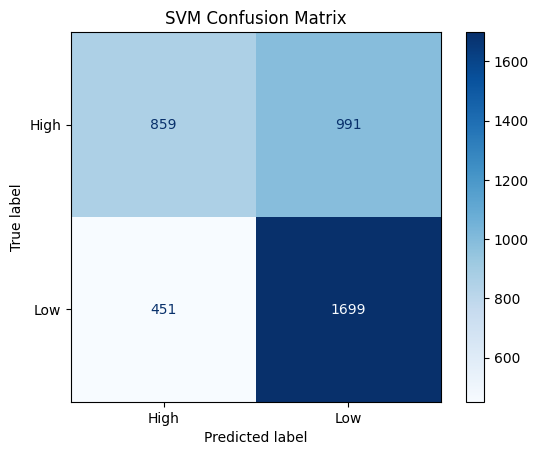

In [25]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(cmap="Blues")

plt.title("SVM Confusion Matrix")
plt.show()

In [26]:
y_prob = svm_model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.6883029541169076


# Hyperparameter Tuning – RandomizedSearchCV

In [27]:
param_dist = {
    "classifier__C": [0.1, 1, 10, 50, 100],

    "classifier__kernel": ["linear", "rbf", "poly"],

    "classifier__gamma": ["scale", "auto", 0.01, 0.1, 1],

    "classifier__class_weight": [None, "balanced"]
}

In [28]:
random_search = RandomizedSearchCV(
    estimator=svm_model,
    param_distributions=param_dist,
    n_iter=12,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1)
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': [0.1, 1, ...], 'classifier__class_weight': [None, 'balanced'], 'classifier__gamma': ['scale', 'auto', ...], 'classifier__kernel': ['linear', 'rbf', ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`

In [29]:
print("Best Parameters:", random_search.best_params_)

Best Parameters: {'classifier__kernel': 'poly', 'classifier__gamma': 0.01, 'classifier__class_weight': None, 'classifier__C': 10}


In [30]:
print("Best CV F1 Score:", random_search.best_score_)

Best CV F1 Score: 0.7247093673129665


In [31]:
best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))

Accuracy: 0.60075
Precision: 0.5798902051430223
Recall: 0.9334883720930233
F1 Score: 0.7153805025842096


# GridSearchCV

In [35]:
best_params = random_search.best_params_
param_grid = {
    "classifier__C": [
        best_params["classifier__C"] / 2,
        best_params["classifier__C"],
        best_params["classifier__C"] * 2 ],

    "classifier__kernel": [
        best_params["classifier__kernel"]
    ],

    "classifier__gamma": [
        best_params["classifier__gamma"]
    ],

    "classifier__class_weight": [
        best_params["classifier__class_weight"]
    ]
}

In [36]:
grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 3 candidates, totalling 9 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [5.0, 10, ...], 'classifier__class_weight': [None], 'classifier__gamma': [0.01], 'classifier__kernel': ['poly']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto

In [37]:
print("Best Grid Parameters:", grid_search.best_params_)
print("Best Grid CV Score:", grid_search.best_score_)

Best Grid Parameters: {'classifier__C': 20, 'classifier__class_weight': None, 'classifier__gamma': 0.01, 'classifier__kernel': 'poly'}
Best Grid CV Score: 0.728651286823391


In [38]:
final_model = grid_search.best_estimator_
final_pred = final_model.predict(X_test)
print("Final Accuracy:", accuracy_score(y_test, final_pred))
print("Final Precision:", precision_score(y_test, final_pred))
print("Final Recall:", recall_score(y_test, final_pred))
print("Final F1 Score:", f1_score(y_test, final_pred))

Final Accuracy: 0.61425
Final Precision: 0.5919418358073311
Final Recall: 0.9088372093023256
Final F1 Score: 0.7169326729040543


In [39]:
print(classification_report(
    y_test,
    final_pred,
    target_names=le.classes_))

              precision    recall  f1-score   support

        High       0.72      0.27      0.39      1850
         Low       0.59      0.91      0.72      2150

    accuracy                           0.61      4000
   macro avg       0.66      0.59      0.56      4000
weighted avg       0.65      0.61      0.57      4000



In [40]:
new_customer = pd.DataFrame([{
    "Age": 35,
    "EmploymentYears": 8.0,
    "AnnualIncome": 600000,
    "LoanAmount": 300000,
    "LoanTenureMonths": 36,
    "CreditScore": 720,
    "ExistingLoans": 1,
    "LatePayments": 0,
    "DebtToIncomeRatio": 0.5,
    "HomeOwnership": "own",
    "LoanPurpose": "personal",
    "EmploymentType": "salaried",
    "BankBalance": 150000
}])

In [41]:
prediction = final_model.predict(new_customer)
result = le.inverse_transform(prediction)
print("Predicted Credit Risk:", result[0])

Predicted Credit Risk: Low


In [42]:
joblib.dump(final_model, "credit_risk_model.pkl")
joblib.dump(le, "label_encoder.pkl")
print("Model saved successfully!")

Model saved successfully!


In [43]:
loaded_model = joblib.load("credit_risk_model.pkl")
loaded_encoder = joblib.load("label_encoder.pkl")

In [44]:
prediction = loaded_model.predict(new_customer)
result = loaded_encoder.inverse_transform(prediction)
print("Predicted Credit Risk:", result[0])

Predicted Credit Risk: Low
